# kappa map construction and weighted signal

- real data
- mock data (25 light cones)
- random rotated data (~100 realizations)

S/N ratio estimates:
- signal: real-random
- noise: from random rotation (background)
- shot noise: fluctuation from different cosmology, estimated from mock data

In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils
from scipy.stats import chi2

In [ ]:
# Combine EE signal across fields with per-field covariance from mocks

name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field
number_galaxies = []

tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concat(dats)
    dat = dat[np.isin(dat['hsc_y3_zbin'], tomo_bin)]
    number_galaxies.append(len(dat))

procedures = [
    'KSI-masking-smooth k',
    'inpainting-KSI-masking-smooth k',
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking',
    'inpainting-smooth g-KSI-masking'
]

full_slice = slice(0, 14)
n_mock = 25
mode_names = ['EE', 'EB', 'BB']

array2dict_norandom = lambda arr: {['ls', 'EE', 'EB', 'BB'][i]: arr[:, i] for i in range(arr.shape[1])}
array2dict_k = lambda arr: {['ls', 'EE', 'EB', 'BB', 'EE_rm', 'EE_std', 'EB_rm', 'EB_std', 'BB_rm', 'BB_std'][i]: arr[:, i] for i in range(arr.shape[1])}

In [4]:
print('\n'.join(name_fields))

XMM
VVDS
GAMA09H
GAMA15H
WIDE12H
HECTOMAP


# Plot HECTOMAP for instance

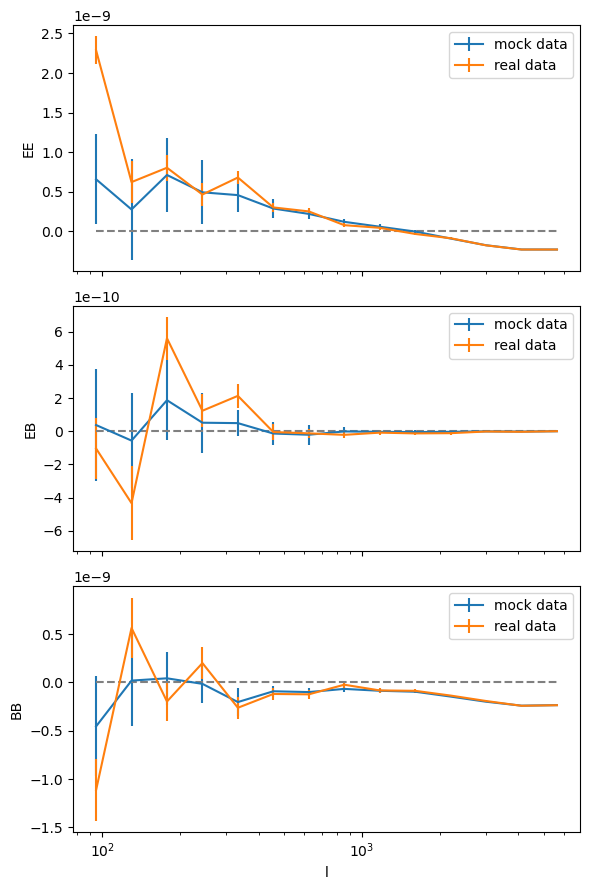

In [5]:
field = 'HECTOMAP'
procedure = 'KSI-masking-smooth k'

stat_k = array2dict_k(np.loadtxt(f'results/Cl_results_{field}_{procedure}.txt'))
# ls, EE, EB, BB, EE_rm, EE_std, EB_rm, EB_std, BB_rm, BB_std
stat_k_mock = [
    array2dict_norandom(np.loadtxt(f'results/Cl_results_{field}_cone{i}_KSI-masking-smooth k.txt'))
    for i in range(1, 26)
]


EE_real = stat_k['EE'] - stat_k['EE_rm']
EB_real = stat_k['EB'] - stat_k['EB_rm']
BB_real = stat_k['BB'] - stat_k['BB_rm']

EE_mock = np.array([stat_k_mock[i]['EE'] - stat_k['EE_rm'] for i in range(len(stat_k_mock))])
EB_mock = np.array([stat_k_mock[i]['EB'] - stat_k['EB_rm'] for i in range(len(stat_k_mock))])
BB_mock = np.array([stat_k_mock[i]['BB'] - stat_k['BB_rm'] for i in range(len(stat_k_mock))])



fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)

ax = axes[0]
ax.errorbar(stat_k['ls'], EE_mock.mean(axis=0), EE_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], EE_real, stat_k['EE_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('EE')
ax.legend()

ax = axes[1]
ax.errorbar(stat_k['ls'], EB_mock.mean(axis=0), EB_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], EB_real, stat_k['EB_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('EB')
ax.legend()
# ax.set_xscale('log')

ax = axes[2]
ax.errorbar(stat_k['ls'], BB_mock.mean(axis=0), BB_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], BB_real, stat_k['BB_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('BB')
ax.set_xlabel('l')
ax.legend()
# ax.set_xscale('log')
ax.set_xscale('log')

plt.tight_layout()

In [51]:
def weighted_average(mode_name, pipeline, _slice, weight='inverse_cov', add_random=False):
    signals = []
    covs = []
    for field in name_fields:
        # Real
        stat_k = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_{pipeline}.txt"))
        ee_real = stat_k[mode_name] - stat_k[f'{mode_name}_rm']

        # Mocks (for covariance)
        stat_k_mock = [
            array2dict_norandom(np.loadtxt(f"results/Cl_results_{field}_cone{i}_{pipeline}.txt"))
            for i in range(1, n_mock + 1)
        ]
        ee_mock = np.array([m[mode_name] - stat_k[f'{mode_name}_rm'] for m in stat_k_mock])

        s = ee_real[_slice]
        C = np.cov(ee_mock[:, _slice], rowvar=False)

        if add_random:
            rand_var = stat_k[f'{mode_name}_std'][_slice] ** 2
            C_rand = np.diag(rand_var)
            C += C_rand

        signals.append(s)
        covs.append(C)
        ls = stat_k['ls'][_slice]

    signals = np.array(signals)  # (n_field, nbin)
    nbin = signals.shape[1]

    # weighted with # of galaxies in each field
    if weight == 'galaxy_number':
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()
        s_mean = np.average(signals, axis=0, weights=w)
        C_mean = np.tensordot(w**2, np.array(covs), axes=(0, 0)) / (wsum**2)
        chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return ls, s_mean, C_mean, chi2_val
    elif weight == 'inverse_cov':
    # 3) Inverse-cov weighted (recommended): s_icov, C_icov
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)
        for s, C in zip(signals, covs):
            # use solve for better stability than explicit inverse
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b

        # S/N for combined signal (pick which combo you want)
        chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)

        return ls, s_icov, C_icov, chi2_val
    else:
        raise ValueError("Invalid weight option")


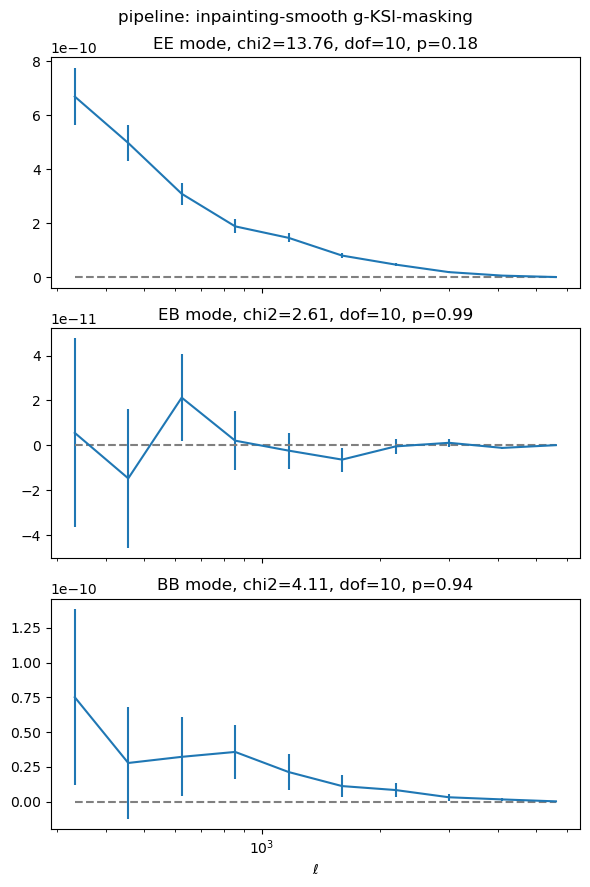

In [41]:
procedure = procedures[4]
selected_slice = slice(4, 14)

fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
for mode_name, ax in zip(['EE', 'EB', 'BB'], axes):
    ls, s_icov, C_icov, SN_icov = weighted_average(mode_name, procedure, selected_slice, add_random=True)
    ax.errorbar(ls, s_icov, np.sqrt([C_icov[i,i] for i in range(len(ls))]))
    ax.hlines(0, ls.min(), ls.max(), linestyles='--', colors='grey')
    ax.set_title(f'{mode_name} mode, chi2={SN_icov:.2f}, dof={len(ls)}, p={chi2.sf(SN_icov, len(ls)):.2f}')
axes[-1].semilogx()
axes[-1].set_xlabel(r'$\ell$')
plt.suptitle(f'pipeline: {procedure}')
plt.tight_layout()

plt.savefig(f'figs/weighted_average/all_weighted_result_{procedure}_{selected_slice.start}-{selected_slice.stop}_w1_addrand.pdf')

In [42]:
procedures

['KSI-masking-smooth k',
 'inpainting-KSI-masking-smooth k',
 'smooth g-inpainting-KSI-masking',
 'smooth g-KSI-masking',
 'inpainting-smooth g-KSI-masking']

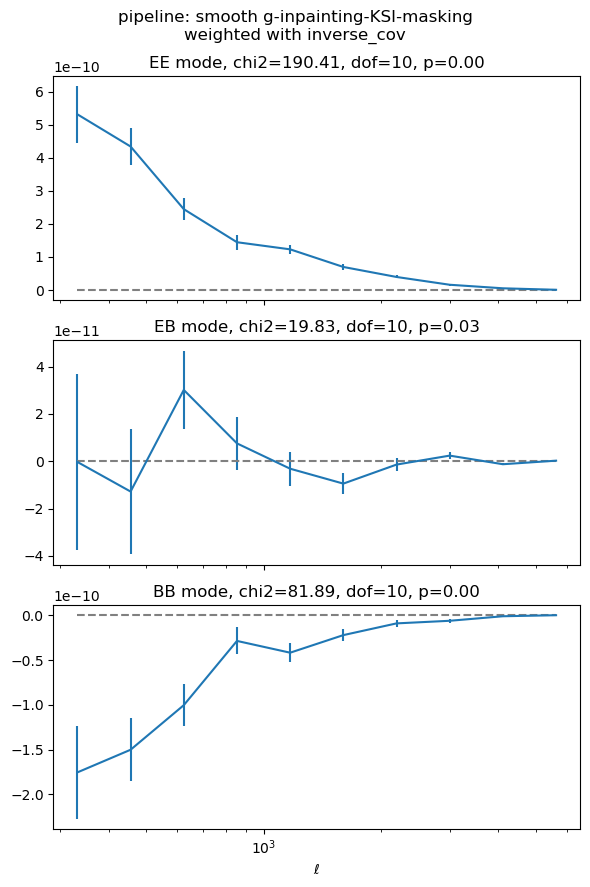

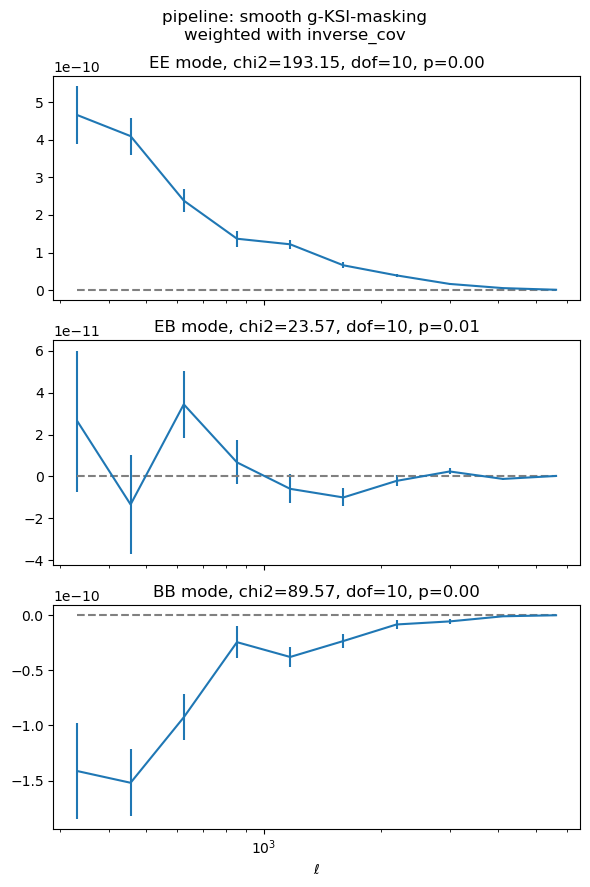

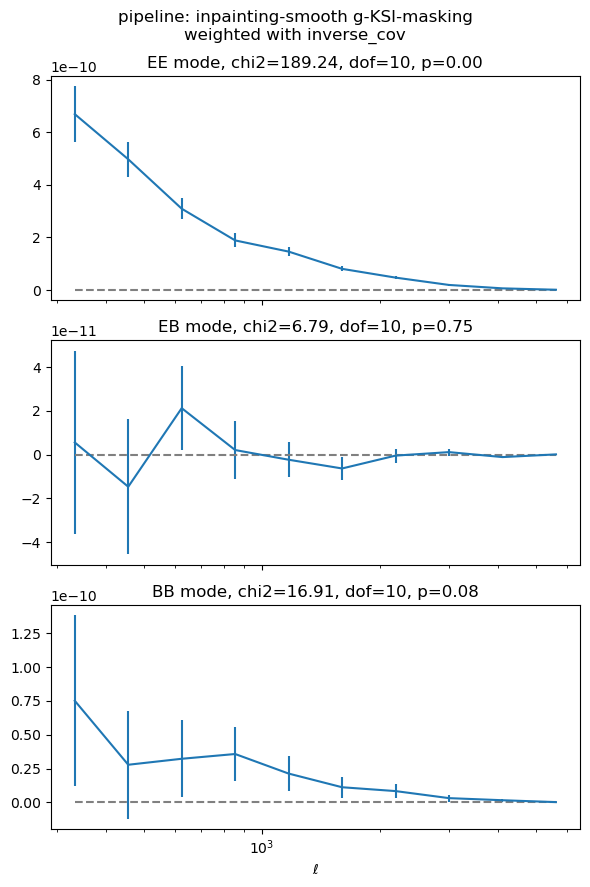

In [ ]:
selected_slice = slice(4, 14)
weight = 'inverse_cov'  # 'inverse_cov' or 'galaxy_number'
add_random = True
for procedure in procedures[2:]:
    fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
    for mode_name, ax in zip(['EE', 'EB', 'BB'], axes):
        ls, s_icov, C_icov, SN_icov = weighted_average(mode_name, procedure, selected_slice, weight=weight, add_random=add_random)
        ax.errorbar(ls, s_icov, np.sqrt([C_icov[i,i] for i in range(len(ls))]))
        ax.hlines(0, ls.min(), ls.max(), linestyles='--', colors='grey')
        ax.set_title(f'{mode_name} mode, chi2={SN_icov:.2f}, dof={len(ls)}, p={chi2.sf(SN_icov, len(ls)):.2f}')
    axes[-1].semilogx()
    axes[-1].set_xlabel(r'$\ell$')
    plt.suptitle(f'pipeline: {procedure}\nweighted with {weight}')
    plt.tight_layout()

    suffix_str = ''
    if weight == 'inverse_cov':
        suffix_str = 'w1'
    elif weight == 'galaxy_number':
        suffix_str = 'w2'
    if add_random:
        suffix_str += '_addrand'

    plt.savefig(f'figs/weighted_average/all_weighted_result_{procedure}_{selected_slice.start}-{selected_slice.stop}_{suffix_str}.pdf')
    plt.show()